In [1]:
import pandas as pd

from churnlens.features.preprocessing import FEATURES, TARGET

train = pd.read_csv("../data/processed/train.csv")
X_train = train[FEATURES]
y_train = train[TARGET]

spw = (y_train == 0).sum() / (y_train == 1).sum()
print(X_train.shape, "churn rate:", round(y_train.mean(), 3), "scale_pos_weight:", round(spw, 2))

(5634, 19) churn rate: 0.265 scale_pos_weight: 2.77


In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate

from churnlens.models.pipelines import MODEL_NAMES, build_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

rows = []
for name in MODEL_NAMES:
    pipe = build_pipeline(name, scale_pos_weight=spw)
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"model": name}
    for metric in scoring:
        vals = scores[f"test_{metric}"]
        row[metric] = f"{vals.mean():.3f} +/- {vals.std():.3f}"
    rows.append(row)

results = pd.DataFrame(rows).set_index("model")
results

d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Gauriii\Projects

,roc_auc,pr_auc,precision,recall,f1
model,,,,,
dummy,0.500 +/- 0.000,0.265 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000
logistic_regression,0.846 +/- 0.012,0.660 +/- 0.019,0.517 +/- 0.019,0.801 +/- 0.038,0.628 +/- 0.023
random_forest,0.845 +/- 0.009,0.655 +/- 0.020,0.539 +/- 0.012,0.766 +/- 0.028,0.632 +/- 0.014
xgboost,0.846 +/- 0.011,0.667 +/- 0.018,0.525 +/- 0.015,0.793 +/- 0.027,0.632 +/- 0.019


In [3]:
from sklearn.model_selection import cross_val_predict

oof = {}
for name in ["logistic_regression", "random_forest", "xgboost"]:
    pipe = build_pipeline(name, scale_pos_weight=spw)
    oof[name] = cross_val_predict(
        pipe, X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]
    print(name, "done")

logistic_regression done
random_forest done


d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:29:17] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:29:20] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:29:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:29:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain,

xgboost done


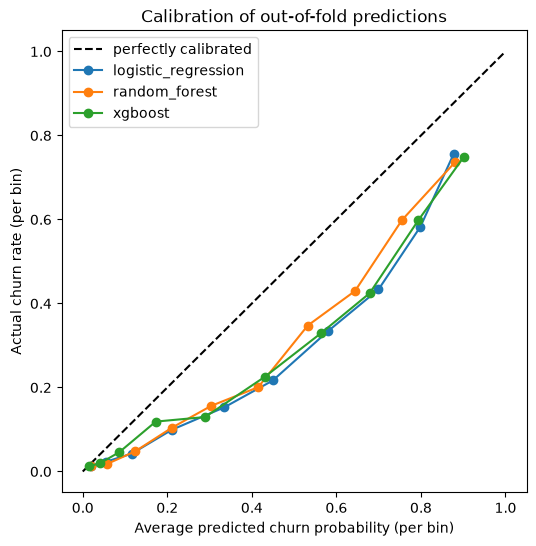

In [4]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
for name, p in oof.items():
    frac_actual, mean_predicted = calibration_curve(
        y_train, p, n_bins=10, strategy="quantile"
    )
    ax.plot(mean_predicted, frac_actual, marker="o", label=name)
ax.set_xlabel("Average predicted churn probability (per bin)")
ax.set_ylabel("Actual churn rate (per bin)")
ax.set_title("Calibration of out-of-fold predictions")
ax.legend()
plt.show()

In [5]:
from sklearn.metrics import brier_score_loss, roc_auc_score

rows = []
for name, p in oof.items():
    rows.append({
        "model": name,
        "roc_auc": round(roc_auc_score(y_train, p), 3),
        "brier": round(brier_score_loss(y_train, p), 3),
        "mean_predicted": round(p.mean(), 3),
        "actual_churn_rate": round(y_train.mean(), 3),
    })
pd.DataFrame(rows).set_index("model")

,roc_auc,brier,mean_predicted,actual_churn_rate
model,,,,
logistic_regression,0.845,0.165,0.414,0.265
random_forest,0.845,0.157,0.394,0.265
xgboost,0.846,0.160,0.397,0.265


In [6]:
from sklearn.calibration import CalibratedClassifierCV

model_names = ["logistic_regression", "random_forest", "xgboost"]
cal_oof = {}

for name in model_names:
    for method in ["sigmoid", "isotonic"]:
        base = build_pipeline(name, scale_pos_weight=spw)
        calibrated = CalibratedClassifierCV(base, method=method, cv=5)
        cal_oof[(name, method)] = cross_val_predict(
            calibrated, X_train, y_train, cv=cv, method="predict_proba"
        )[:, 1]
        print(name, method, "done")

logistic_regression sigmoid done
logistic_regression isotonic done
random_forest sigmoid done
random_forest isotonic done


d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:33:19] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:33:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:33:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:33:24] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain,

xgboost sigmoid done


d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:33:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:33:57] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:33:59] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\Gauriii\Projects\ChurnLens\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:34:00] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  bst.update(dtrain,

xgboost isotonic done


In [7]:
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

rows = []
for name in model_names:
    candidates = {"raw": oof[name],
                  "sigmoid": cal_oof[(name, "sigmoid")],
                  "isotonic": cal_oof[(name, "isotonic")]}
    for version, p in candidates.items():
        rows.append({
            "model": name,
            "version": version,
            "roc_auc": round(roc_auc_score(y_train, p), 3),
            "brier": round(brier_score_loss(y_train, p), 3),
            "log_loss": round(log_loss(y_train, p), 3),
            "mean_predicted": round(p.mean(), 3),
        })
pd.DataFrame(rows).set_index(["model", "version"])

roc_auc  brier  log_loss  mean_predicted
model               version                                           
logistic_regression raw         0.845  0.165     0.491           0.414
                    sigmoid     0.845  0.135     0.417           0.266
                    isotonic    0.844  0.135     0.418           0.266
random_forest       raw         0.845  0.157     0.473           0.394
                    sigmoid     0.846  0.135     0.418           0.265
                    isotonic    0.846  0.135     0.428           0.265
xgboost             raw         0.846  0.160     0.478           0.397
                    sigmoid     0.847  0.135     0.418           0.266
                    isotonic    0.846  0.134     0.421           0.266

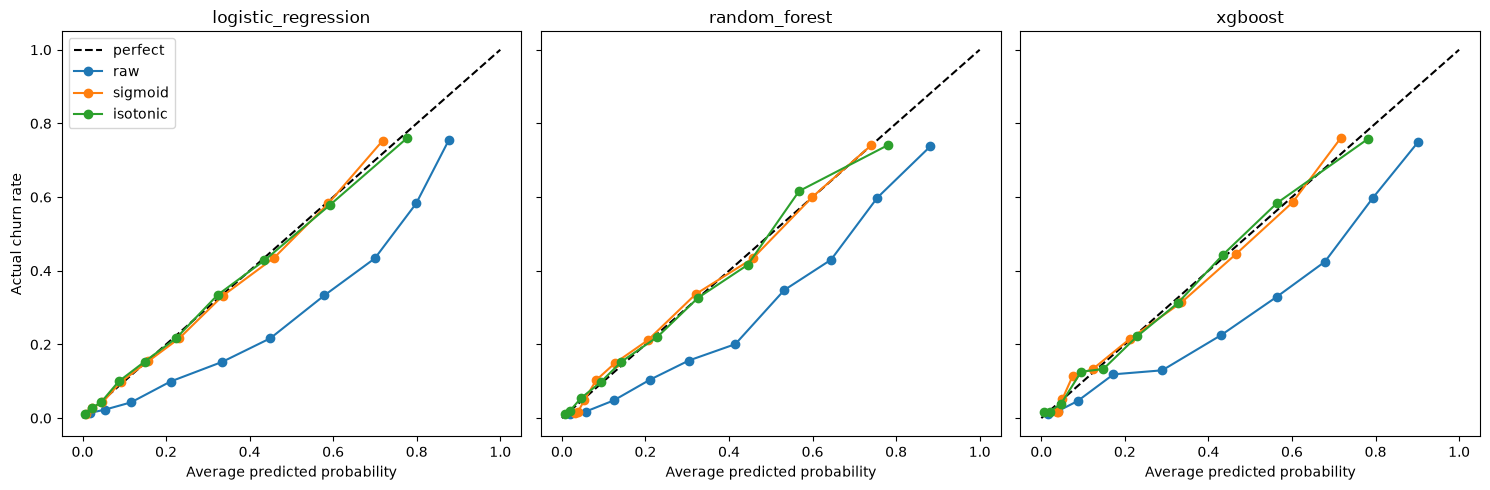

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, name in zip(axes, model_names):
    ax.plot([0, 1], [0, 1], "k--", label="perfect")
    for label, p in [("raw", oof[name]),
                     ("sigmoid", cal_oof[(name, "sigmoid")]),
                     ("isotonic", cal_oof[(name, "isotonic")])]:
        frac_actual, mean_pred = calibration_curve(y_train, p, n_bins=10, strategy="quantile")
        ax.plot(mean_pred, frac_actual, marker="o", label=label)
    ax.set_title(name)
    ax.set_xlabel("Average predicted probability")
axes[0].set_ylabel("Actual churn rate")
axes[0].legend()
plt.tight_layout()
plt.show()